# UMAP with example images framed around the plot

This notebook:
1. Computes a 2-D UMAP embedding of your features.
2. Picks a set of points from the embedding (k-means representatives, farthest-point sampling, random, or your own indices).
3. Draws the UMAP scatter in the middle and lines the selected points' images up around it in a rectangle, with a leader line from each image to its point.

Points are matched to border slots with a minimum-total-length assignment, which guarantees that leader lines never cross.

It runs as-is on the scikit-learn **digits** dataset. To use your own data, edit only the **Load data** cell.

In [1]:
# !pip install umap-learn scikit-learn matplotlib pillow

import os
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
from microfilm.colorify import multichannel_to_rgb
from montage_utils.montage_utils import (
    create_and_save_single_image_panel,
    make_multi_channel_image_array,
)
from notebook_init_utils.notebook_init_utils import bandicoot_check, init_notebook
from PIL import Image
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

root_dir, init_notebook = init_notebook()

images_base_dir = bandicoot_check(
    bandicoot_mount_path=pathlib.Path(os.path.expanduser("~/mnt/bandicoot")),
    root_dir=root_dir,
)
RNG_SEED = 0

# Output figures and a local, in-repo cache of rendered multi-channel composites.
# The cache lets small plot tweaks re-run fast: each composite is built from the
# raw channel z-stacks only once, then reloaded from this directory thereafter.
figures_dir = root_dir / "figures" / "assembled_figure_3" / "figures"
image_cache_dir = root_dir / "figures" / "assembled_figure_3" / "data" / "image_cache"
figures_dir.mkdir(parents=True, exist_ok=True)
image_cache_dir.mkdir(parents=True, exist_ok=True)

# All image-frame figures are written as pages of this one multi-page PDF.
umap_image_frame_pdf_path = figures_dir / "umap_image_frame.pdf"

## Load data

In [2]:
umap_data_file_path = pathlib.Path(
    f"{root_dir}/1.EDA/results/umap/3D_scfs_umap.parquet"
).resolve(strict=True)
umap_data = pd.read_parquet(umap_data_file_path)

In [3]:
# Stage subdirectory holding the display-ready (illum-corrected) channel z-stacks.
image_stage = "zstack_images"


def _raw_image_filepath_channelx(row):
    well_fov = row["Metadata_Experiment_WellFOV"].replace("_", "-")
    patient_tumor = row["Metadata_Biology_PatientTumor"]
    return f"{images_base_dir}/data/{patient_tumor}/{image_stage}/{well_fov}"


umap_data[f"Metadata_raw_image_filepath"] = umap_data.apply(
    lambda row: _raw_image_filepath_channelx(row), axis=1
)
umap_data.head()

,Metadata_Biology_PatientID,Metadata_Biology_PatientTumor,Metadata_Biology_TumorType,Metadata_Experiment_Class,Metadata_Experiment_Dose,Metadata_Experiment_ImageSet,Metadata_Experiment_PlateID,Metadata_Experiment_Target,Metadata_Experiment_TherapeuticCategories,Metadata_Experiment_Treatment,...,Metadata_Object_WellSingleCellCount,Metadata_cqc_nan_detected,Metadata_cqc_organoid_flagged,Metadata_cqc_missing_parent_organoid,Metadata_cqc_small_nuclei_outlier,Metadata_cqc_large_nuclei_outlier,Metadata_cqc_mass_displacement_outlier,UMAP1,UMAP2,Metadata_raw_image_filepath
0,NF0014,NF0014_T1,cNF,Small Molecule,1.0,NF0014_T1__NF0014_T1__E5__F2,NF0014_T1,PI3K and HDAC inhibitor,Investigational,Fimepinostat,...,4,False,False,False,False,False,False,0.007412,7.566259,/home/lippincm/mnt/bandicoot/NF1_organoid_data...
1,NF0014,NF0014_T1,cNF,Small Molecule,1.0,NF0014_T1__NF0014_T1__E5__F2,NF0014_T1,PI3K and HDAC inhibitor,Investigational,Fimepinostat,...,4,False,False,False,False,False,False,0.236822,7.506579,/home/lippincm/mnt/bandicoot/NF1_organoid_data...
2,NF0014,NF0014_T1,cNF,Small Molecule,1.0,NF0014_T1__NF0014_T1__E5__F2,NF0014_T1,PI3K and HDAC inhibitor,Investigational,Fimepinostat,...,4,False,False,False,False,False,False,-1.754111,8.474119,/home/lippincm/mnt/bandicoot/NF1_organoid_data...
3,NF0014,NF0014_T1,cNF,Small Molecule,1.0,NF0014_T1__NF0014_T1__D5__F2,NF0014_T1,PI3K and HDAC inhibitor,Investigational,Fimepinostat,...,18,False,False,True,False,False,False,3.472141,8.368134,/home/lippincm/mnt/bandicoot/NF1_organoid_data...
4,NF0014,NF0014_T1,cNF,Small Molecule,1.0,NF0014_T1__NF0014_T1__D5__F2,NF0014_T1,PI3K and HDAC inhibitor,Investigational,Fimepinostat,...,18,False,False,True,False,False,False,4.819744,6.565176,/home/lippincm/mnt/bandicoot/NF1_organoid_data...


In [4]:
# Wire the real UMAP data into the names the plotting cells expect.
# embedding: (N, 2) UMAP coordinates; images: aligned well-FOV directory paths
# (each rendered on demand into a multi-channel composite by `_load_image`).
embedding = umap_data[["UMAP1", "UMAP2"]].to_numpy()
images = umap_data["Metadata_raw_image_filepath"].to_numpy()

# Point-coloring schemes requested: tumor type, patient, treatment (drug + dose).
labels_tumor = umap_data["Metadata_Biology_TumorType"].to_numpy()
labels_patient = umap_data["Metadata_Biology_PatientTumor"].to_numpy()
labels_treatment = (
    umap_data["Metadata_Experiment_Treatment"].astype(str)
    + " "
    + umap_data["Metadata_Experiment_Dose"].map(
        lambda d: f"{d:g}uM" if pd.notna(d) else "NA"
    )
).to_numpy()

# Default labels used by any single-labeling helper call.
labels = labels_tumor

# ---------------------------------------------------------------------------
# Canonical palettes (copied from utils/r_plot_themes.r so the Python figures
# match the manuscript R figures). A gray fallback covers any label missing
# from a palette (e.g. a NaN tumor type).
# ---------------------------------------------------------------------------
MISSING_COLOR = "#CCCCCC"

tumor_type_palette = {
    "cNF": "#1B9E77",
    "pNF": "#D95F02",
    "MPNST": "#7570B3",
    "Other": "#999999",
}

# tab20_palette_for_patients applied in the canonical patient order from
# tumor_type_lookup (r_plot_themes.r).
_patient_order = [
    "NF0014_T1",
    "NF0014_T2",
    "NF0016_T1",
    "NF0018_T6",
    "NF0021_T1",
    "NF0030_T1",
    "NF0035_T1",
    "NF0037_T1",
    "NF0040_T1",
    "NF0055_T1",
    "SARCO219_T2",
    "SARCO361_T1",
]
_tab20_patients = [
    "#1f77b4",
    "#aec7e8",
    "#ff7f0e",
    "#ffbb78",
    "#2ca02c",
    "#98df8a",
    "#d62728",
    "#ff9896",
    "#9467bd",
    "#c5b0d5",
    "#8c564b",
    "#c49c94",
    "#e377c2",
    "#f7b6d2",
    "#7f7f7f",
    "#c7c7c7",
    "#bcbd22",
    "#dbdb8d",
    "#17becf",
    "#9edae5",
]
patient_palette = {p: _tab20_patients[i] for i, p in enumerate(_patient_order)}

# custom_treatment_palette (r_plot_themes.r), keyed by drug name.
drug_palette = {
    "DMSO": "#A6A6A6",
    "Staurosporine": "#3F468C",
    "Fimepinostat": "#3DCCA8",
    "Copanlisib": "#3DCACC",
    "Everolimus": "#3DA4CC",
    "Rapamycin": "#3D7DCC",
    "Sapanisertib": "#3D57CC",
    "Vistusertib": "#493DCC",
    "Panobinostat": "#CC8029",
    "ARV-825": "#CCAB29",
    "Imatinib": "#6047CC",
    "Nilotinib": "#8347CC",
    "Cabozantinib": "#A647CC",
    "Linsitinib": "#CA47CC",
    "Binimetinib": "#D92B7F",
    "Mirdametinib": "#D92B51",
    "Trametinib": "#D9342B",
    "Selumetinib": "#D9622B",
    "Onalespib": "#6CA642",
    "Digoxin": "#BF3078",
    "Ketotifen": "#238C83",
    "Trabectedin": "#388C5B",
}
# Treatment labels are "<drug> <dose>uM"; color them by the drug (the canonical
# palette is per-drug), so both doses of a drug share its color.
treatment_palette = {
    lab: drug_palette.get(str(lab).rsplit(" ", 1)[0], MISSING_COLOR)
    for lab in pd.unique(labels_treatment)
}

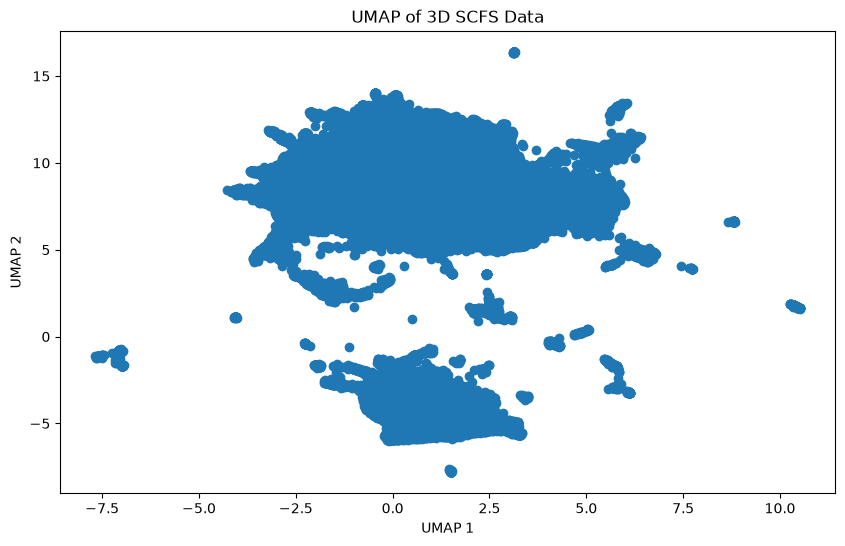

In [5]:
# plot the loaded data
plt.figure(figsize=(10, 6))
plt.scatter(umap_data["UMAP1"], umap_data["UMAP2"])
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of 3D SCFS Data")
plt.show()

## Choose which points to show

- `"kmeans"`: cluster the embedding into `n` groups and take the real point closest to each centre — good coverage of the dense regions.
- `"fps"`: farthest-point sampling — good coverage of the whole shape, including outliers.
- `"per_label"`: `n_per_label` random points from each class.
- `"random"`
- or just pass a list of indices you care about.

In [6]:
def select_points(
    embedding, n=24, method="kmeans", labels=None, n_per_label=2, seed=RNG_SEED
):
    rng = np.random.default_rng(seed)
    N = len(embedding)
    if method == "kmeans":
        km = KMeans(n_clusters=n, n_init=10, random_state=seed).fit(embedding)
        idx = []
        for c in km.cluster_centers_:
            d = np.linalg.norm(embedding - c, axis=1)
            d[idx] = np.inf  # avoid duplicates
            idx.append(int(np.argmin(d)))
        return np.array(idx)
    if method == "fps":
        idx = [int(rng.integers(N))]
        d = np.linalg.norm(embedding - embedding[idx[0]], axis=1)
        for _ in range(n - 1):
            i = int(np.argmax(d))
            idx.append(i)
            d = np.minimum(d, np.linalg.norm(embedding - embedding[i], axis=1))
        return np.array(idx)
    if method == "per_label":
        assert labels is not None, "per_label needs labels"
        idx = []
        for u in np.unique(labels):
            members = np.flatnonzero(labels == u)
            idx.extend(
                rng.choice(members, size=min(n_per_label, len(members)), replace=False)
            )
        return np.array(idx)
    if method == "random":
        return rng.choice(N, size=n, replace=False)
    raise ValueError(method)

## Layout helpers

The scatter is scaled into a box (keeping its aspect ratio). Images are spread over the four sides of a larger rectangle around it so neighbours (including at corners) never overlap; they shrink automatically if there are too many. Points are matched to slots with the minimum-total-length assignment (Hungarian algorithm). A minimum-length matching never contains two crossing segments, so leader lines don't cross.

In [7]:
def label_colors(labels, palette=None):
    """Map categorical labels to colors.

    Returns (colors, lut): `colors` is a per-point RGBA/colorlist aligned to
    `labels` (or None if labels is None), and `lut` is an ordered
    {label: color} dict for building a legend.

    If `palette` (a {label: color} dict, e.g. a canonical palette from
    utils/r_plot_themes.r) is given, it is used directly and any label missing
    from it falls back to MISSING_COLOR. Otherwise colors are generated: up to
    10 categories use tab10, up to 20 use tab20, and more are drawn from the
    combined tab20/tab20b/tab20c (60 distinct colors).
    """
    if labels is None:
        return None, {}
    labels = np.asarray(labels)
    uniq = list(pd.unique(labels))
    if palette is not None:
        fallback = globals().get("MISSING_COLOR", "#CCCCCC")
        lut = {lab: palette.get(lab, fallback) for lab in uniq}
    else:
        n = len(uniq)
        if n <= 10:
            colors_list = [plt.get_cmap("tab10")(i) for i in range(n)]
        elif n <= 20:
            colors_list = [plt.get_cmap("tab20")(i) for i in range(n)]
        else:
            base = (
                list(plt.get_cmap("tab20").colors)
                + list(plt.get_cmap("tab20b").colors)
                + list(plt.get_cmap("tab20c").colors)
            )
            colors_list = [base[i % len(base)] for i in range(n)]
        lut = {lab: colors_list[i] for i, lab in enumerate(uniq)}
    colors = [lut[lab] for lab in labels]
    return colors, lut


# Channel -> color for the multi-channel composite, matching
# montage_utils.create_and_save_single_image_panel (sorted channels 405, 488, 555, 640).
COMPOSITE_CMAPS = ["pure_cyan", "pure_green", "pure_magenta", "pure_red"]
# Per-channel percentile contrast stretch (low, high) applied before colorizing.
# Clipping the low 3% to black and the top 0.5% to full brightens dim signal
# while keeping the background clean (plain min-max leaves composites too dim).
COMPOSITE_CONTRAST = (3.0, 99.5)


def _composite_rgb(channel_array):
    """Contrast-stretch each channel (per COMPOSITE_CONTRAST), colorize with
    COMPOSITE_CMAPS, and blend into one uint8 RGB image."""
    arr = channel_array.astype(np.float64)
    lo_p, hi_p = COMPOSITE_CONTRAST
    stretched = np.empty_like(arr)
    for k in range(arr.shape[0]):
        a = arr[k]
        p_lo, p_hi = np.percentile(a, [lo_p, hi_p])
        stretched[k] = np.clip((a - p_lo) / (p_hi - p_lo + 1e-9), 0.0, 1.0)
    rgb = multichannel_to_rgb(
        stretched, cmaps=COMPOSITE_CMAPS[: arr.shape[0]], rescale_type="min_max"
    )[0]
    return (np.clip(np.asarray(rgb)[..., :3], 0.0, 1.0) * 255).astype(np.uint8)


def _cache_path(img_dir):
    """Local cache filename for a well-FOV directory's composite: keyed by
    patient / stage / well-FOV and the contrast setting, so changing the
    contrast invalidates stale renders automatically."""
    p = pathlib.Path(img_dir)
    lo_p, hi_p = COMPOSITE_CONTRAST
    key = f"{p.parent.parent.name}__{p.parent.name}__{p.name}__c{lo_p:g}-{hi_p:g}"
    return image_cache_dir / f"{key}.png"


def _load_image(img):
    """Load an image for display in the UMAP frame.

    A path to a well-FOV *directory* of channel tiffs is rendered as the
    multi-channel composite (same pipeline/colors as
    montage_utils.create_and_save_single_image_panel: middle z-slice per
    channel via `make_multi_channel_image_array`, colorized via
    `multichannel_to_rgb`). Renders are cached as PNGs under
    `image_cache_dir` and reloaded on later runs. An array or single-image
    path falls back to a contrast-stretched grayscale view.
    """
    is_path = isinstance(img, (str, bytes, pathlib.Path)) or hasattr(img, "__fspath__")
    if is_path and os.path.isdir(img):
        cache_fp = _cache_path(img)
        if cache_fp.exists():
            try:
                return np.asarray(Image.open(cache_fp).convert("RGB"))
            except Exception:
                pass  # corrupt/partial cache entry -> rebuild below
        composite = _composite_rgb(make_multi_channel_image_array(pathlib.Path(img)))
        try:
            Image.fromarray(composite).save(cache_fp)
        except Exception:
            pass  # caching is best-effort; never fail the plot over it
        return composite
    # fallback: single image path or raw array -> grayscale
    if is_path:
        from PIL import ImageSequence

        im = Image.open(img)
        frames = [np.asarray(f) for f in ImageSequence.Iterator(im)]
        arr = np.max(np.stack(frames, axis=0), axis=0) if len(frames) > 1 else frames[0]
    else:
        arr = np.asarray(img)
    if arr.ndim == 2 and arr.dtype != np.uint8:
        arr = arr.astype(np.float64)
        lo, hi = np.percentile(arr, [1, 99])
        if hi > lo:
            arr = np.clip((arr - lo) / (hi - lo), 0.0, 1.0)
        else:
            arr = arr - arr.min()
            peak = arr.max()
            arr = arr / peak if peak else arr
        arr = (arr * 255).astype(np.uint8)
    return arr


def _side_counts(n, hw, hh):
    """Split n images over top/bottom/left/right to maximise the smallest spacing.
    Top/bottom rows include the corners; left/right columns sit between them."""
    best, best_sp = None, -1
    for t in range(1, n + 1):
        for b in range(max(1, t - 1), min(t + 1, n - t) + 1):
            rest = n - t - b
            if rest < 0:
                continue
            l, r = rest // 2 + rest % 2, rest // 2
            sp = min(
                2 * hw / (t - 1) if t > 1 else 4 * hw,
                2 * hw / (b - 1) if b > 1 else 4 * hw,
                2 * hh / (l + 1),
                2 * hh / (r + 1),
            )
            if sp > best_sp + 1e-12:
                best, best_sp = (t, b, l, r), sp
    return best, best_sp


def _rect_slots(center, hw, hh, counts):
    t, b, l, r = counts
    row = lambda k: np.linspace(-hw, hw, k) if k > 1 else np.array([0.0])
    col = lambda k: np.linspace(-hh, hh, k + 2)[1:-1]
    pts = (
        [(x, hh) for x in row(t)]
        + [(x, -hh) for x in row(b)]
        + [(-hw, y) for y in col(l)]
        + [(hw, y) for y in col(r)]
    )
    return np.array(pts) + center


def _assign_slots(points, slots):
    """Minimum total Euclidean length matching. A min-length matching between two
    point sets never has crossing segments, so leader lines don't cross."""
    from scipy.optimize import linear_sum_assignment

    D = np.linalg.norm(points[:, None, :] - slots[None, :, :], axis=2)
    _, cols = linear_sum_assignment(D)
    return cols  # assignment[i] = slot index for point i


def umap_with_image_frame(
    embedding,
    images,
    idx,
    labels=None,
    palette=None,
    img_size=0.11,  # image side length, relative to the larger side of the scatter box
    gap=0.015,  # space between the (scaled) scatter and the image ring
    frame_aspect=2.6,  # >1 widens the image ring horizontally -> wide/rectangular figure
    scatter_fill=0.95,  # scale the scatter out to fill this fraction of the ring interior
    auto_grow=True,  # enlarge crops toward `max_img_size` when few are shown
    max_img_size=0.30,  # cap on crop side length (relative) when auto-growing
    label_bar_loc="top",  # solid label-color bar inside each crop: "top"/"bottom"/None
    label_bar_frac=0.14,  # bar height as a fraction of the crop height
    point_size=6,
    figsize=(32, 13),
    cmap_images="gray",  # used for 2-D (grayscale) images
    legend_title="label",
    title_fontsize=30,
    legend_fontsize=17,
    show_index=False,
    title=None,
    ax=None,
):
    idx = np.asarray(idx)
    n = len(idx)

    # normalise embedding into a box, preserving aspect ratio
    lo, hi = embedding.min(0), embedding.max(0)
    scale = (hi - lo).max()
    E = (embedding - lo) / scale  # in [0, w] x [0, h], max(w, h) = 1
    w, h = E.max(0)
    center = np.array([w / 2, h / 2])

    # Ring half-extents. `frame_aspect` stretches the horizontal extent only.
    def ring_half(s):
        return (w / 2 + gap + s / 2) * frame_aspect, h / 2 + gap + s / 2

    # Fit the crop side length `s` to the number of crops: shrink it when the
    # ring is crowded, and (when `auto_grow`) enlarge it toward `max_img_size`
    # when few crops leave spare room -- so fewer crops are drawn larger.
    # `spacing` is the smallest gap between neighbouring slots; keep it
    # >= s * 1.08 so crops never touch. A one-step look-ahead before growing
    # avoids oscillation at the crossover (spacing/s falls as s grows).
    s = img_size
    for _ in range(400):
        hw, hh = ring_half(s)
        counts, spacing = _side_counts(n, hw, hh)
        if spacing < s * 1.08:
            s *= 0.95
            continue
        if auto_grow and s < max_img_size:
            s_next = min(s * 1.03, max_img_size)
            hw_n, hh_n = ring_half(s_next)
            _, spacing_n = _side_counts(n, hw_n, hh_n)
            if spacing_n >= s_next * 1.08:
                s = s_next
                continue
        break
    s = min(s, max_img_size)
    hw, hh = ring_half(s)
    counts, _ = _side_counts(n, hw, hh)

    slots = _rect_slots(center, hw, hh, counts)

    # Scale the scatter outward so its edges nearly meet the image ring, removing
    # the white gap between the UMAP and the images (per-axis, so it also widens
    # the embedding to fill the wide frame).
    inner_hw = hw - s / 2 - gap
    inner_hh = hh - s / 2 - gap
    fx = scatter_fill * inner_hw / (w / 2) if w else 1.0
    fy = scatter_fill * inner_hh / (h / 2) if h else 1.0
    E = center + (E - center) * np.array([fx, fy])

    pts = E[idx]
    assignment = _assign_slots(pts, slots)

    colors, lut = label_colors(labels, palette=palette)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # background scatter
    ax.scatter(
        E[:, 0],
        E[:, 1],
        s=point_size,
        linewidths=0,
        c=colors if colors is not None else "0.6",
        alpha=0.6,
        zorder=1,
    )
    # highlighted points
    ax.scatter(
        pts[:, 0],
        pts[:, 1],
        s=point_size * 12,
        facecolors="none",
        edgecolors="k",
        linewidths=1.2,
        zorder=4,
    )

    for j, i in enumerate(idx):
        sx, sy = slots[assignment[j]]
        px, py = pts[j]

        # leader line ends at the image edge rather than its centre
        d = np.array([px - sx, py - sy])
        t = min(
            (s / 2) / abs(d[0]) if d[0] else np.inf,
            (s / 2) / abs(d[1]) if d[1] else np.inf,
        )
        ex, ey = sx + d[0] * t, sy + d[1] * t
        ax.plot([px, ex], [py, ey], color="0.35", lw=0.7, zorder=2)

        img = _load_image(images[i])
        # keep image aspect inside the s x s slot
        ih, iw = img.shape[:2]
        if iw >= ih:
            dw, dh = s / 2, s / 2 * ih / iw
        else:
            dw, dh = s / 2 * iw / ih, s / 2
        ax.imshow(
            img,
            extent=(sx - dw, sx + dw, sy - dh, sy + dh),
            cmap=cmap_images if img.ndim == 2 else None,
            interpolation="nearest" if max(ih, iw) < 64 else "antialiased",
            zorder=3,
        )

        edge = colors[i] if colors is not None else "0.3"
        # solid label-color bar inside the crop (top or bottom), so each crop's
        # category is readable even where the thin border is hard to see.
        if label_bar_loc and colors is not None:
            bar_h = 2 * dh * label_bar_frac
            bar_y = sy + dh - bar_h if label_bar_loc == "top" else sy - dh
            ax.add_patch(
                Rectangle(
                    (sx - dw, bar_y),
                    2 * dw,
                    bar_h,
                    fill=True,
                    facecolor=colors[i],
                    edgecolor="none",
                    alpha=0.95,
                    zorder=4.5,
                )
            )
        ax.add_patch(
            Rectangle(
                (sx - dw, sy - dh),
                2 * dw,
                2 * dh,
                fill=False,
                edgecolor=edge,
                lw=2.0,
                zorder=5,
            )
        )
        if show_index:
            ax.text(
                sx - dw,
                sy + dh,
                f" {i}",
                ha="left",
                va="top",
                fontsize=11,
                zorder=6,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.8),
            )

    if lut:
        handles = [
            plt.Line2D([], [], marker="o", ls="", color=c, label=str(l))
            for l, c in lut.items()
        ]
        ncol = 1 if len(lut) <= 14 else 2
        ax.legend(
            handles=handles,
            loc="upper left",
            bbox_to_anchor=(1.005, 1),
            frameon=False,
            title=legend_title,
            fontsize=legend_fontsize,
            title_fontsize=legend_fontsize + 2,
            ncol=ncol,
            handletextpad=0.4,
            labelspacing=0.3,
            borderaxespad=0.0,
        )

    # Tight limits around the ring (small `pad`) to minimise surrounding white space.
    pad = s * 0.12
    ax.set_xlim(center[0] - hw - s / 2 - pad, center[0] + hw + s / 2 + pad)
    ax.set_ylim(center[1] - hh - s / 2 - pad, center[1] + hh + s / 2 + pad)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=title_fontsize)
    return fig, ax

## Plots: wide image frame, colored by canonical palettes

Each metadata scheme (tumor type, patient, treatment) is drawn twice, from two
point-selection strategies shown in **separate plots**:

- **closest** — k-means representatives: the real point closest to each cluster
  centre (covers the dense, typical regions).
- **farthest** — farthest-point sampling: spreads across the whole embedding,
  including the extremes/outliers.

Colors come from `utils/r_plot_themes.r` (`tumor_type_palette`,
`tab20_palette_for_patients`, `custom_treatment_palette`). The frame is wide,
the composites use the brighter `COMPOSITE_CONTRAST`, and renders are cached.

### Colored by tumor type

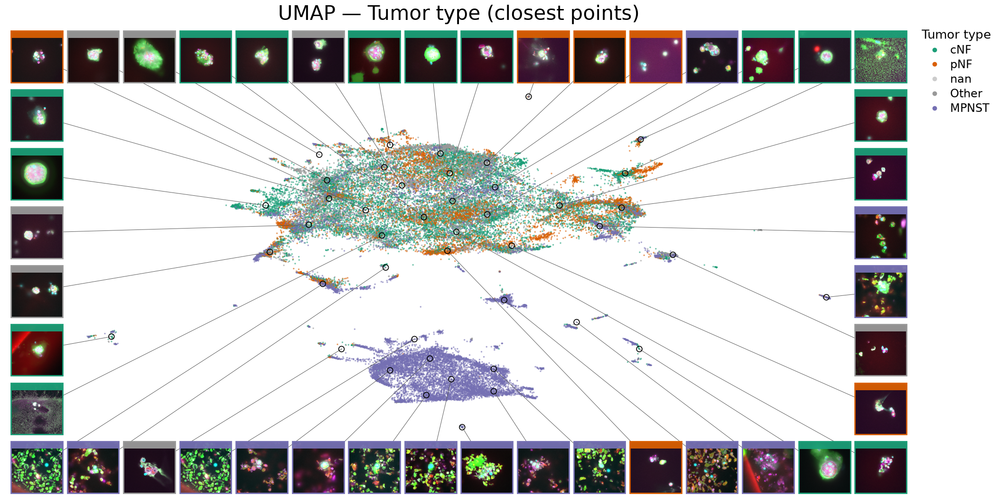

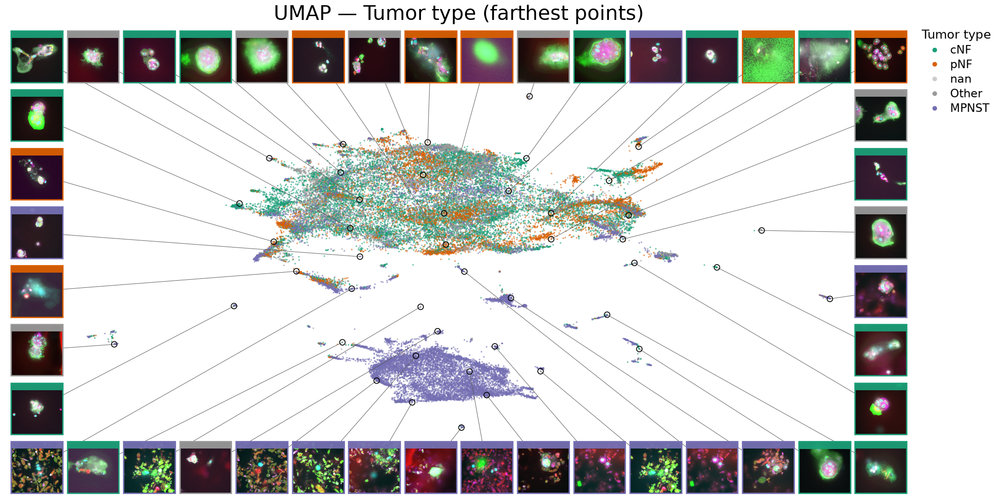

In [8]:
# Two point selections, each shown in its own plot for every labeling.
# `N_IMAGES` is the knob for crop size: lower it to show fewer crops, and
# `umap_with_image_frame(auto_grow=True)` enlarges each crop toward
# `max_img_size` to use the freed space.
N_IMAGES = 44
idx_closest = select_points(
    embedding, n=N_IMAGES, method="kmeans"
)  # closest to cluster centres
idx_farthest = select_points(
    embedding, n=N_IMAGES, method="fps"
)  # farthest-point sampling
SELECTIONS = {"closest": idx_closest, "farthest": idx_farthest}


# Single multi-page PDF: every figure below is appended as one page.
# Opened here and closed in the final cell.
pdf = PdfPages(umap_image_frame_pdf_path)


def frame_and_save(labels_arr, palette, legend_title, scheme):
    """Draw the wide image frame for `labels_arr` from both the closest and
    farthest point selections, appending each as a page to the shared `pdf`."""
    for sel_name, sel_idx in SELECTIONS.items():
        fig, ax = umap_with_image_frame(
            embedding,
            images,
            sel_idx,
            labels=labels_arr,
            palette=palette,
            legend_title=legend_title,
            title=f"UMAP — {legend_title} ({sel_name} points)",
        )
        pdf.savefig(fig, dpi=600, bbox_inches="tight")
        plt.show()


frame_and_save(labels_tumor, tumor_type_palette, "Tumor type", "tumor_type")

### Colored by patient

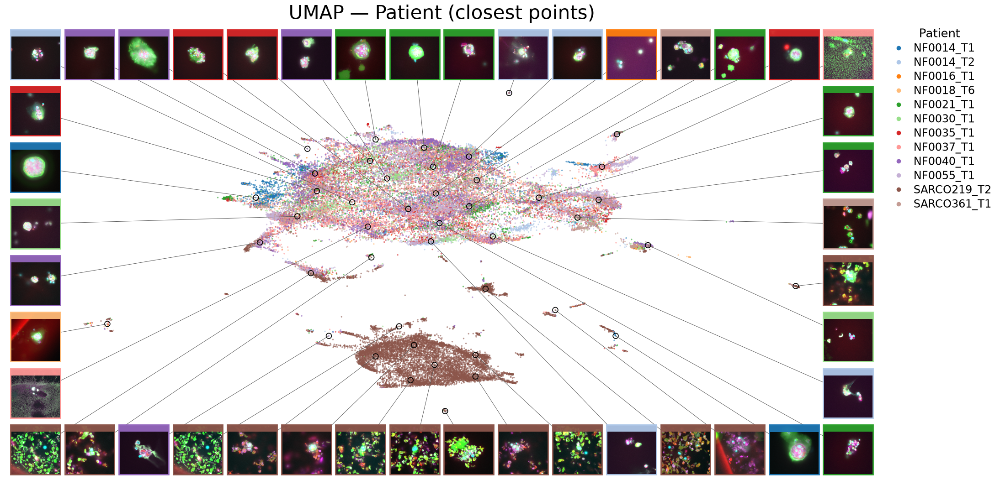

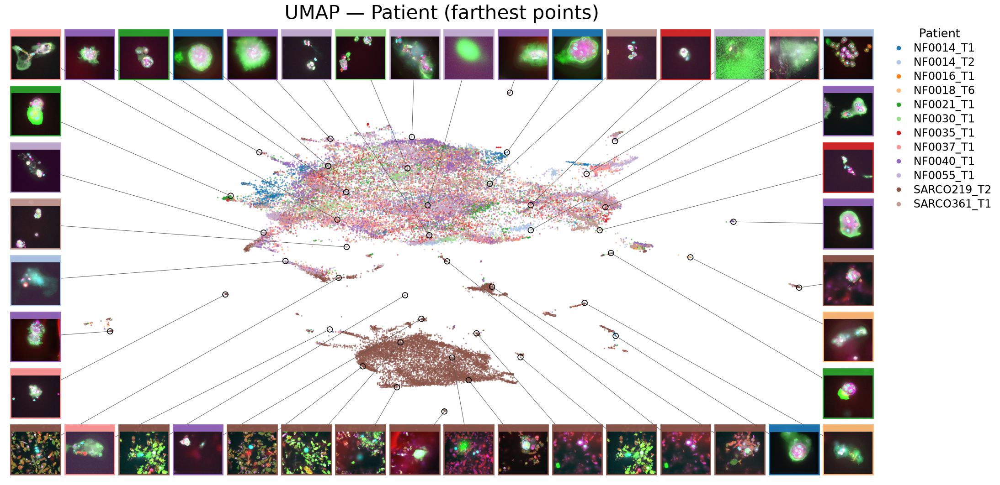

In [9]:
frame_and_save(labels_patient, patient_palette, "Patient", "patient")

### Colored by treatment (drug + dose)

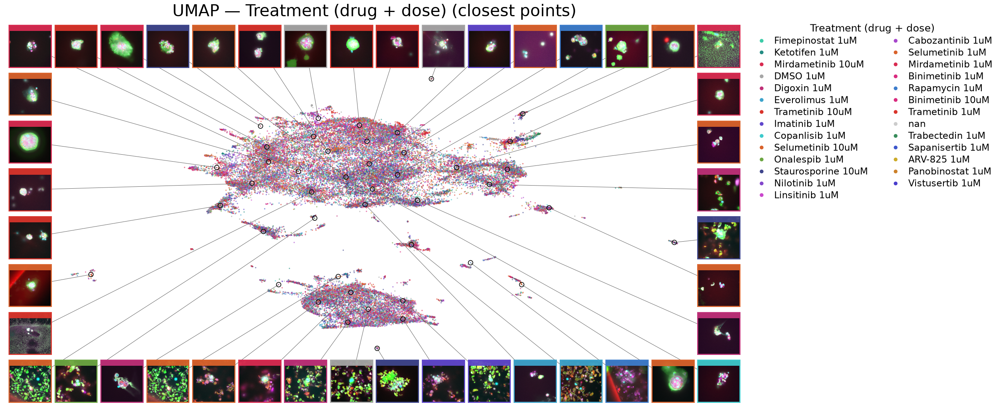

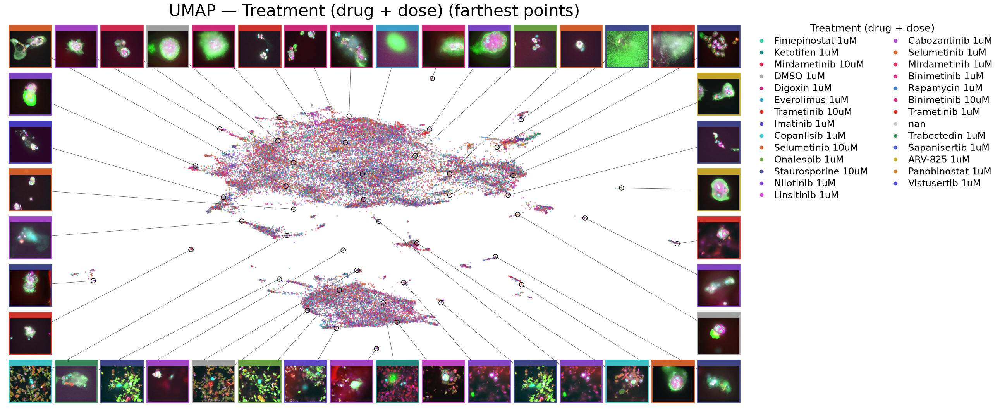

In [10]:
frame_and_save(
    labels_treatment, treatment_palette, "Treatment (drug + dose)", "treatment"
)

### All three together

One figure stacking the same wide image frame colored by tumor type, patient,
and treatment. It reuses the shared points and the cached composites, so it adds
little runtime on top of the individual plots.

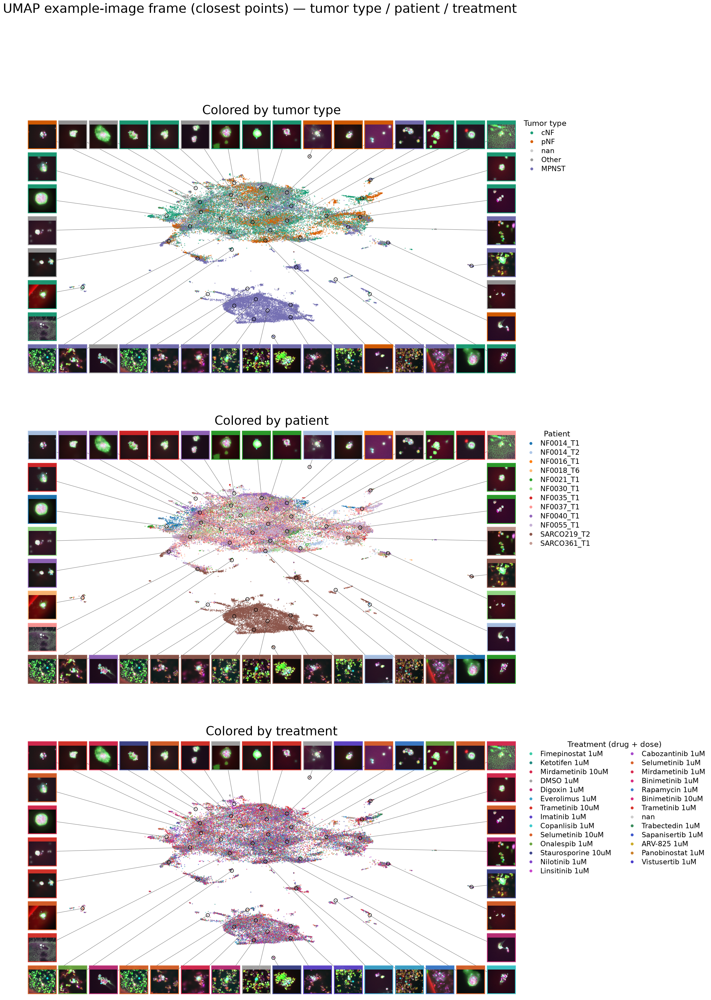

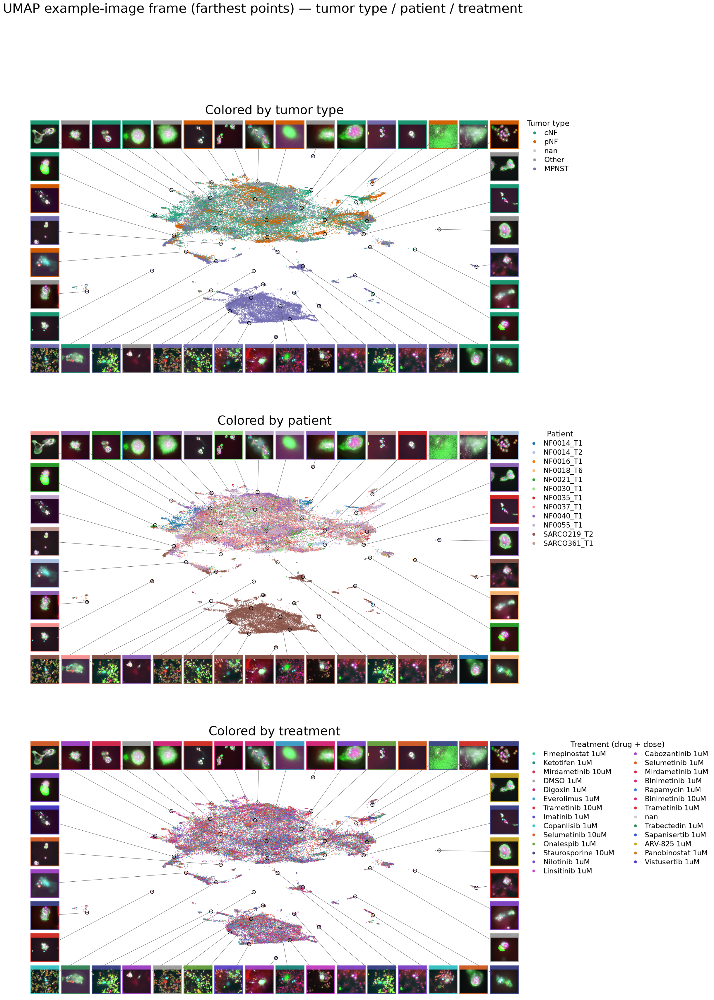

In [11]:
# All three colorings stacked in one figure, once per selection (closest / farthest).
schemes = [
    (labels_tumor, tumor_type_palette, "Tumor type", "Colored by tumor type"),
    (labels_patient, patient_palette, "Patient", "Colored by patient"),
    (
        labels_treatment,
        treatment_palette,
        "Treatment (drug + dose)",
        "Colored by treatment",
    ),
]

for sel_name, sel_idx in SELECTIONS.items():
    fig, axes = plt.subplots(len(schemes), 1, figsize=(32, 13 * len(schemes)))
    for ax_i, (lab, pal, leg, ttl) in zip(np.atleast_1d(axes), schemes):
        umap_with_image_frame(
            embedding,
            images,
            sel_idx,
            labels=lab,
            palette=pal,
            legend_title=leg,
            title=ttl,
            ax=ax_i,
        )
    fig.suptitle(
        f"UMAP example-image frame ({sel_name} points) — tumor type / patient / treatment",
        fontsize=32,
    )
    pdf.savefig(fig, dpi=300, bbox_inches="tight")
    plt.show()

# Finalise the single multi-page PDF.
pdf.close()